# Slit illumination and lamp centroid shifts

Use the accepted ZShooter prescription with a 0.33 arcsec slit. Compare a centered point illumination with the same source displaced **+0.0825 arcsec across the slit**, under the configured natural-seeing and AO effective PSFs. The wavelength spectrum combines the repository's ThAr, Ne and Ar line lists, with their documented per-list normalization and intrinsic R=200000.

These are illumination experiments: atmospheric absorption, sky emission and ADC displacement are disabled. Instrumental throughput and detector geometry remain configured. Optical background is measured and subtracted. Counts are rates with an arbitrary lamp normalization. The raw difference retains slit losses; the flux-normalized difference isolates redistribution.

Isolated synthetic lines exercise the same configured PSF, slit and projection separately from real-lamp blends. Predicted shifts use the centroid of the transmitted Moffat illumination and the configured cross-slit dispersion. The effective PSF is the simulation input; this experiment does not add a separate instrumental PSF convolution.

In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from scipy.integrate import quad
from astropy.constants import c
import scopesim as sim
from scopesim.effects import SpectralTraceList
from zs_scopesim_tools.sources import lamp_flat, _read_lamp_lines
from zs_scopesim_tools.comparison import detector_rates, trace_pixel_grid, boxcar_sum, line_width, trace_line_profiles
from zs_scopesim_tools.helpers import configure_irdb_path, warning_prevent_sync_alt_ra_dec, disable_scopesim_progress_bars, set_scopesim_log_level

workspace = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path/'env/zshooter-stack.toml').exists())
irdb = Path(configure_irdb_path())
output = workspace/'validation/xshooter/data/lamps'
output.mkdir(parents=True, exist_ok=True)
set_scopesim_log_level('error')
lamp = lamp_flat(resolving_power=200000, wave_step=.01*u.AA).spectra[0]
catalog = _read_lamp_lines(irdb/'ZShooter_v2/lamp_lines')
catalog.sort('wave')
properties = {'!OBS.airmass': 1.1, '!OBS.seeing': .65, '!OBS.mjdobs': 60310.25, '!INST.vis_curr_slit': .33, '!INST.nir_curr_slit': .33, '!INST.include_diffuse_emissivity': False}
commands = sim.UserCommands(use_instrument='ZShooter_v2', properties=properties)
warning_prevent_sync_alt_ra_dec(commands)
for document in commands.yaml_dicts:
    if 'effects' in document:
        document['effects'] = [effect for effect in document['effects'] if effect['name'] not in ('atmo_transmission', 'continuum_emission', 'airglow_and_interline_continuum', 'adc_residuals')]
train = sim.OpticalTrain(commands)
traces, = train.optics_manager.get_all(SpectralTraceList)
orders = {}
for trace_id, trace in traces.spectral_traces.items():
    index, axis, pixels, centers, edges = trace_pixel_grid(train, trace_id)
    coordinates = train.trace_detector_coordinates(xi=np.array([-2., 2.])*u.arcsec, wavelengths={trace_id: edges.mean().reshape(1)})
    spatial_axis = 'y' if axis == 'x' else 'x'
    width = int(np.ceil(np.ptp(coordinates[f'detector_{spatial_axis}'].value)))
    size = train.detector_managers[index][0].data.shape[0 if axis == 'x' else 1]
    keep = np.flatnonzero((centers >= width/2) & (centers < size-width/2))
    first, last = keep[0], keep[-1]
    orders[trace_id] = {'index': index, 'axis': axis, 'pixels': pixels[first:last+1], 'centers': centers[first:last+1], 'edges': edges[first:last+2], 'widths': np.full(last-first+1, width)}
timings, centroid_rows, image_paths = [], [], {}

In [2]:
def illumination_centroid(psf, fov, eta):
    beta = psf.alpha
    wavelength = psf._sample_kernel_wavelengths(fov.waveset)
    gamma = psf.fwhm(wavelength).to_value(u.arcsec)/(2*np.sqrt(2**(1/beta)-1))
    # Along-slit marginal of the circular Moffat; the 4 arcsec extraction
    # aperture contains its relevant core at these effective FWHMs.
    profile = lambda position: np.mean((1+((position-eta)/gamma)**2)**(.5-beta)/gamma)
    transmitted = quad(profile, -.165, .165, epsabs=1e-10)[0]
    moment = quad(lambda position: position*profile(position), -.165, .165, epsabs=1e-10)[0]
    return moment/transmitted

def observe_lamp(eta, label):
    target = None if eta is None else sim.Source(x=[0.], y=[eta], ref=[0], weight=[1.], spectra=[lamp])
    for plane in train.image_planes:
        plane.data.fill(0)
    started = perf_counter()
    with disable_scopesim_progress_bars():
        train.observe(target, update=False)
    timings.append((label, eta, perf_counter()-started))
    print(label, eta, f'{timings[-1][2]:.1f} s', flush=True)
    return detector_rates(train)

synthetic_centers = {}
for trace_id, data in orders.items():
    channel, order = trace_id.rsplit('_', 1)
    spectrograph = traces._spectrographs[channel]
    center = spectrograph.central_wave(int(order)).to_value(u.um)
    candidates = center + (np.array([.2, .5, .8])-.5)*spectrograph.fsr(int(order)).to_value(u.um)
    synthetic_centers[trace_id] = candidates[(candidates > data['edges'][0].value*1.002) & (candidates < data['edges'][-1].value*.998)]

line_wave = catalog['wave']/10000
neighboring_distance = np.minimum(np.r_[np.inf, np.diff(line_wave)], np.r_[np.diff(line_wave), np.inf])
for label, ao in [('natural', False), ('AO', True)]:
    train['seeing_psf'].meta['enable_ao'] = ao
    background = observe_lamp(None, label)
    centered = [image-sky for image, sky in zip(observe_lamp(0., label), background)]
    displaced = [image-sky for image, sky in zip(observe_lamp(.0825, label), background)]
    image_paths[label] = []
    for index, (first, second) in enumerate(zip(centered, displaced)):
        paths = [output/f'{label}_{kind}_{index}.npy' for kind in ('centered', 'displaced')]
        np.save(paths[0], first)
        np.save(paths[1], second)
        image_paths[label].append(paths)
    lamp_profiles = {}
    for trace_id, data in orders.items():
        index = data['index']
        lamp_profiles[trace_id] = [boxcar_sum(frame[index], data['axis'], data['pixels'], data['centers'], data['widths']) for frame in (centered, displaced)]
    synthetic = [trace_line_profiles(train, orders, synthetic_centers, eta=eta) for eta in (0., .0825)]
    for trace_id, data in orders.items():
        trace = traces.spectral_traces[trace_id]
        fov, = [fov for fov in train.fov_manager.fovs if fov.trace_id == trace_id]
        trace._set_dispersion(trace.wave_min, trace.wave_max, pixsize=train.image_planes[data['index']].header['CDELT1D'])
        wave = (data['edges'][1:]+data['edges'][:-1])/2
        slit_delta = abs(trace.slit_dispersion(line_wave))*.33
        isolated = (line_wave > wave[0].value*1.001) & (line_wave < wave[-1].value*.999) & (catalog['amplitude'] > .001) & (neighboring_distance > 5*slit_delta)
        eta_center = illumination_centroid(train['seeing_psf'], fov, .0825)-illumination_centroid(train['seeing_psf'], fov, 0.)
        for kind, centers in [('lamp', line_wave[isolated]), ('synthetic', synthetic_centers[trace_id])]:
            profiles = lamp_profiles[trace_id] if kind == 'lamp' else [entry[trace_id] for entry in synthetic]
            for center in centers:
                window = abs(wave.value-center) < 3*abs(trace.slit_dispersion(center))*.33
                centroids = [center*u.um+(profile[window]*(wave[window]-center*u.um)).sum(dtype=np.float64)/profile[window].sum(dtype=np.float64) for profile in profiles]
                delta = (centroids[1]-centroids[0]).to_value(u.um)
                predicted = trace.slit_dispersion(center)*eta_center
                dispersion = abs(trace.dlam_per_pix(center))
                centroid_rows.append((label, kind, trace_id, center, eta_center, delta/dispersion, predicted/dispersion, c.to_value(u.km/u.s)*delta/center, c.to_value(u.km/u.s)*predicted/center))
centroids = pd.DataFrame(centroid_rows, columns=['psf', 'source', 'trace', 'wavelength_um', 'transmitted_eta_shift_arcsec', 'measured_shift_pixel', 'predicted_shift_pixel', 'measured_shift_km_s', 'predicted_shift_km_s'])
centroids.to_csv(output/'centroid_shifts.csv', index=False)
pd.DataFrame(timings, columns=['psf', 'source_eta_arcsec', 'observe_s']).to_csv(output/'timings.csv', index=False)
display(centroids.groupby(['psf', 'source'])[['measured_shift_pixel', 'predicted_shift_pixel']].agg(['min', 'max']))

natural None 42.4 s
natural 0.0 35.2 s
natural 0.0825 32.0 s
AO None 70.5 s
AO 0.0 60.8 s
AO 0.0825 56.8 s


measured_shift_pixel           predicted_shift_pixel  \
                                   min       max                   min   
psf     source                                                           
AO      lamp                 -0.215462 -0.110635             -0.214624   
        synthetic            -0.209225 -0.111985             -0.207913   
natural lamp                 -0.094808 -0.038836             -0.097254   
        synthetic            -0.095793 -0.040218             -0.096869   

                             
                        max  
psf     source               
AO      lamp      -0.112839  
        synthetic -0.113807  
natural lamp      -0.040296  
        synthetic -0.041408

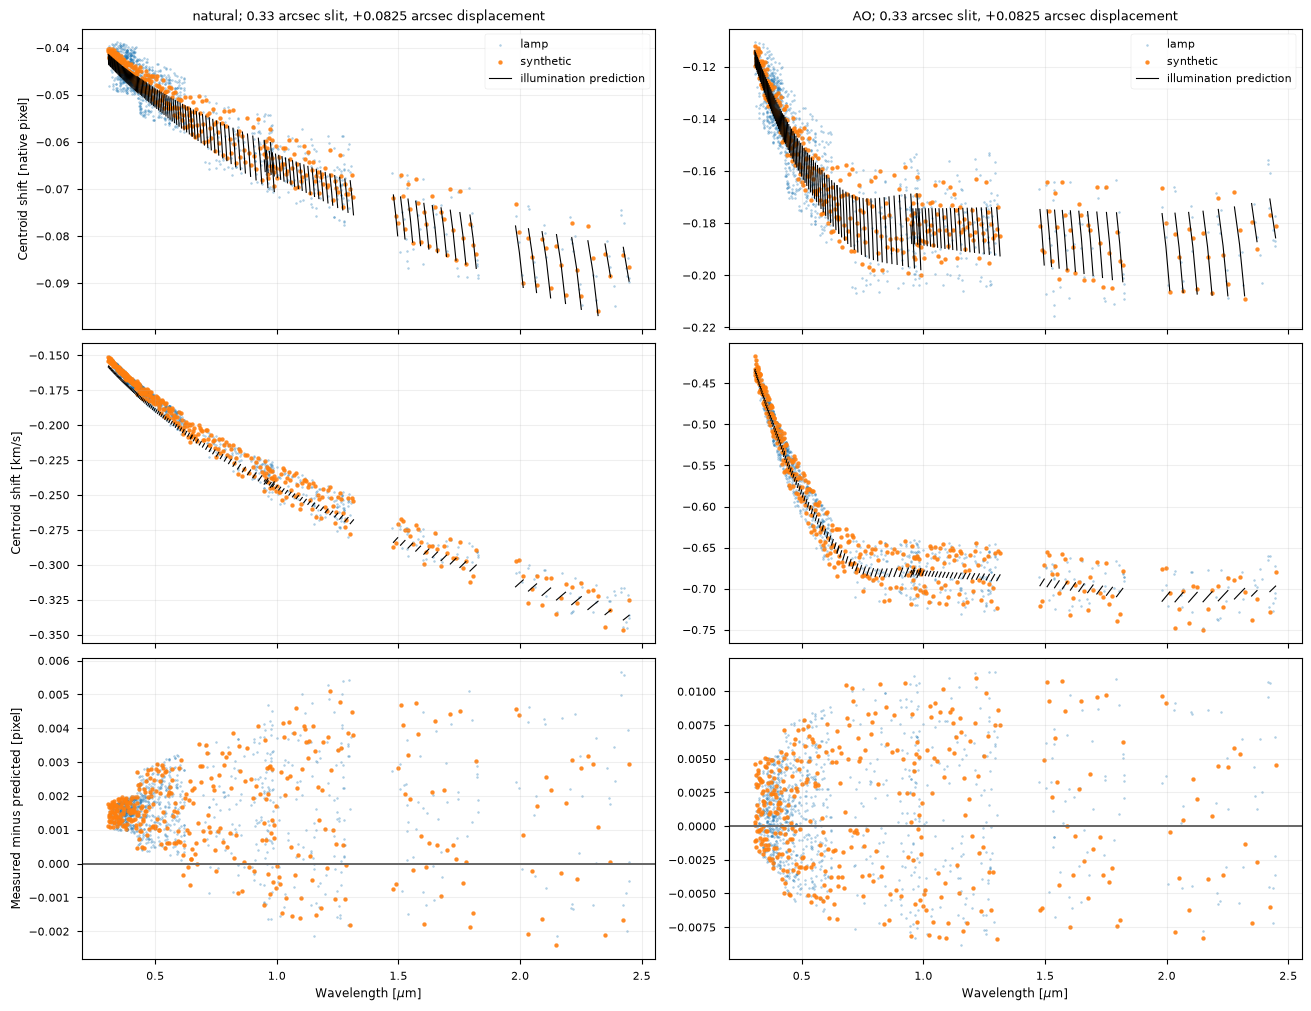

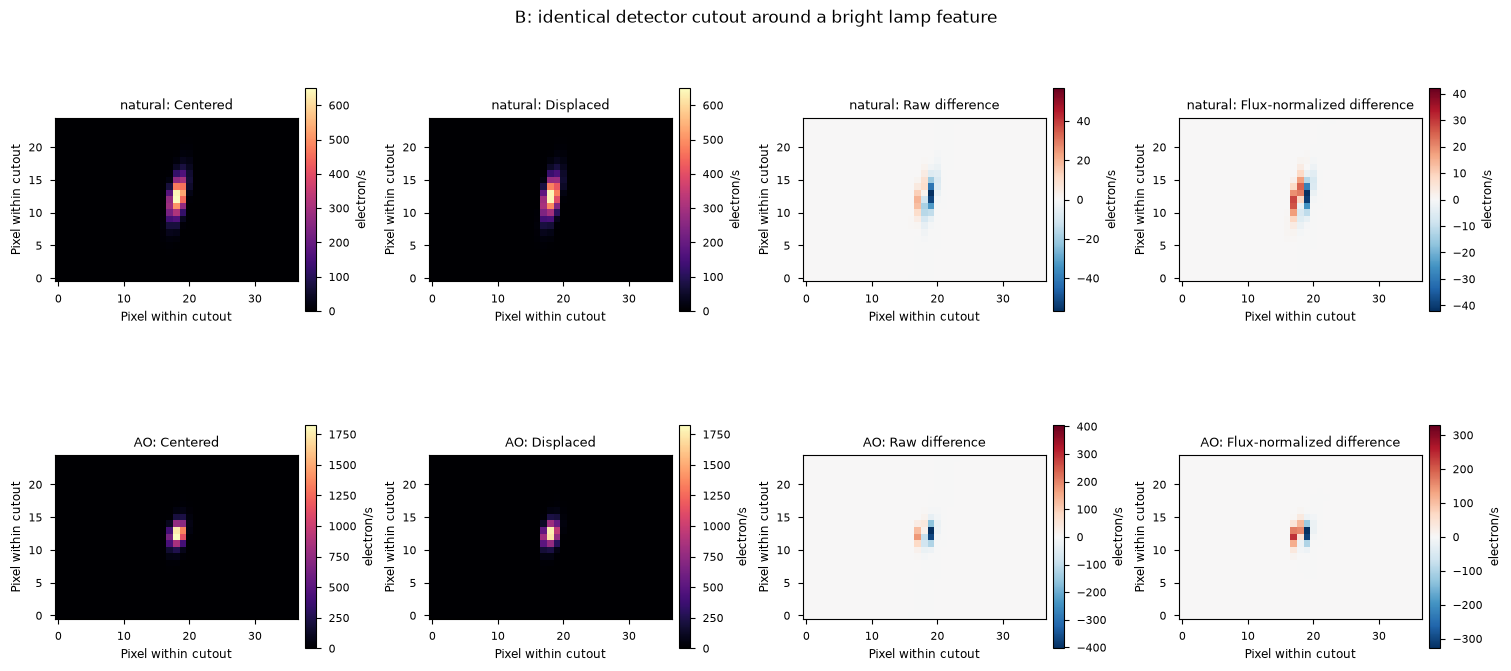

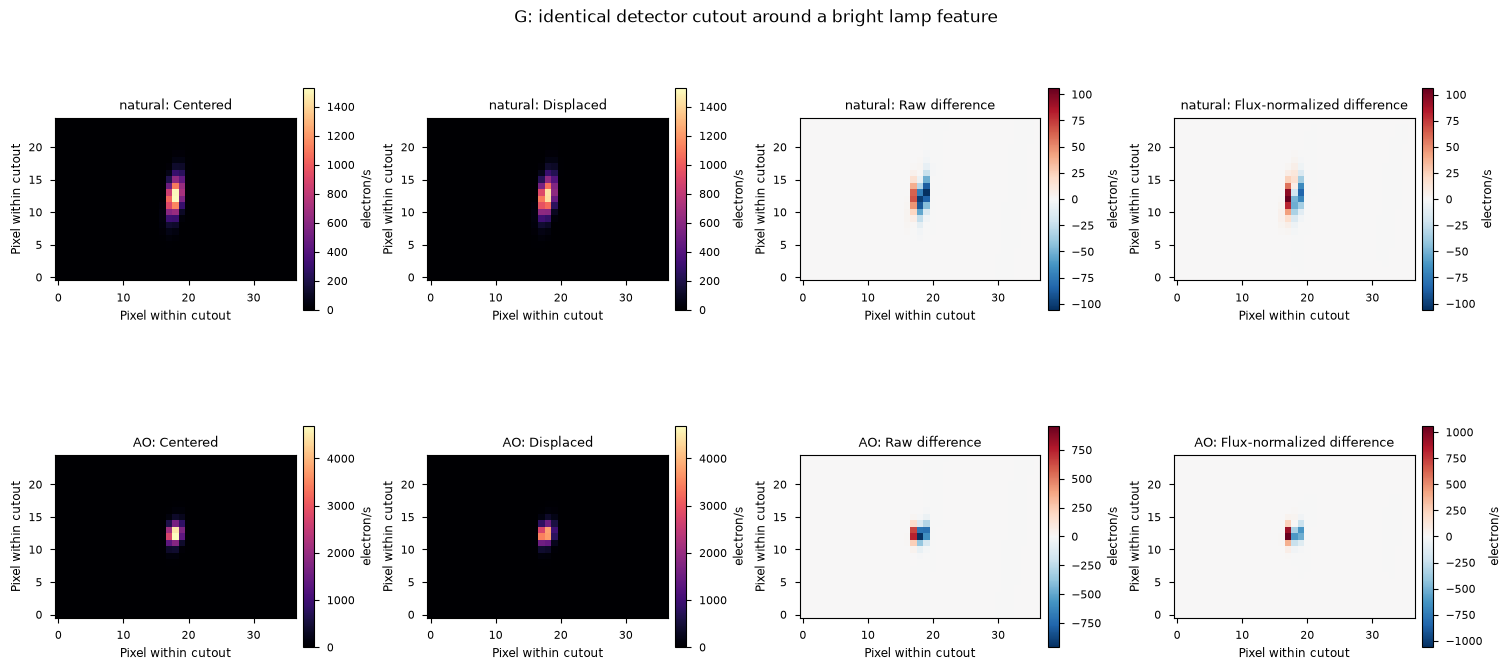

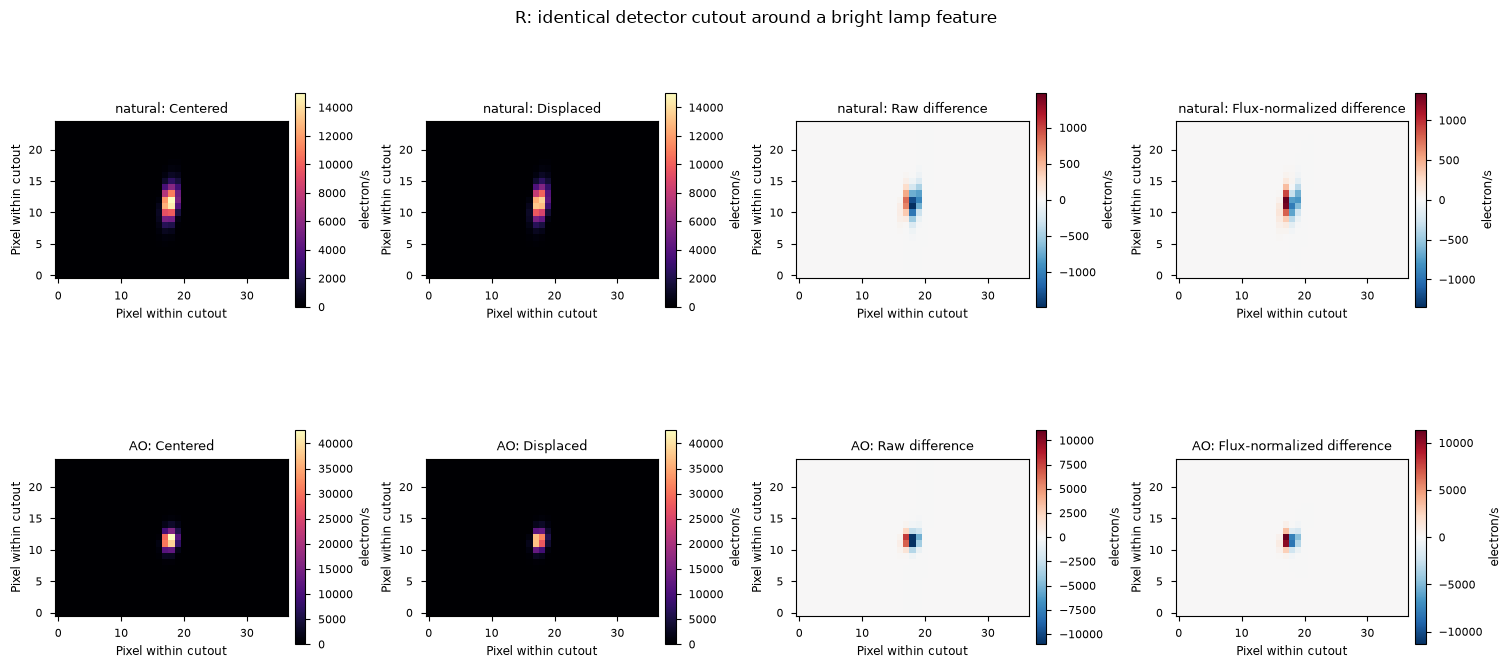

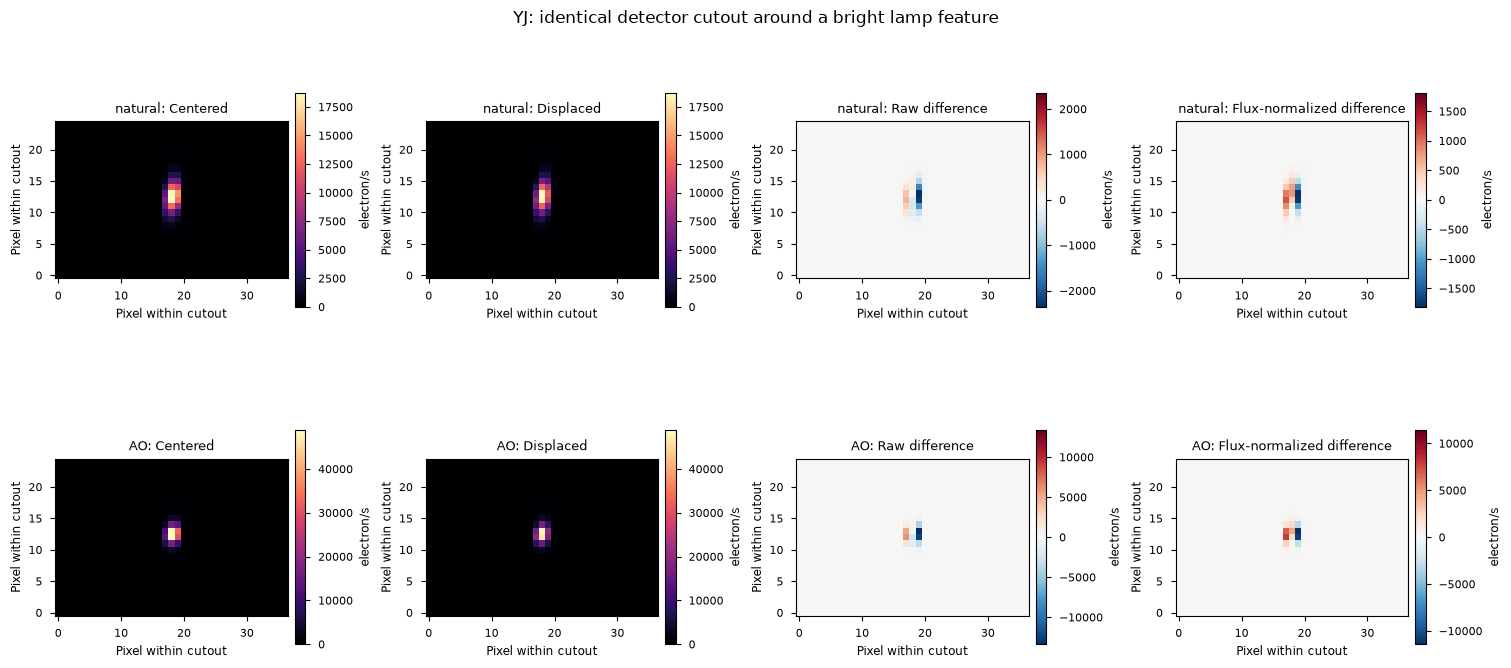

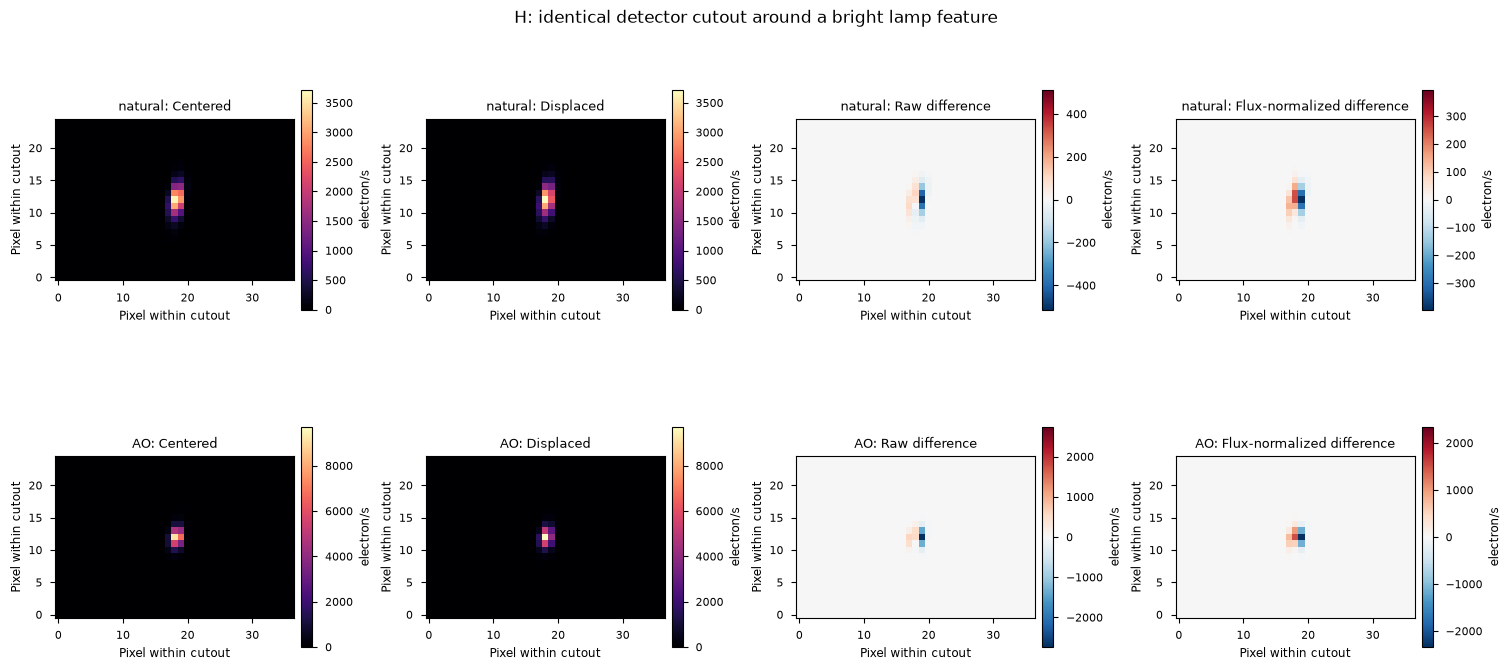

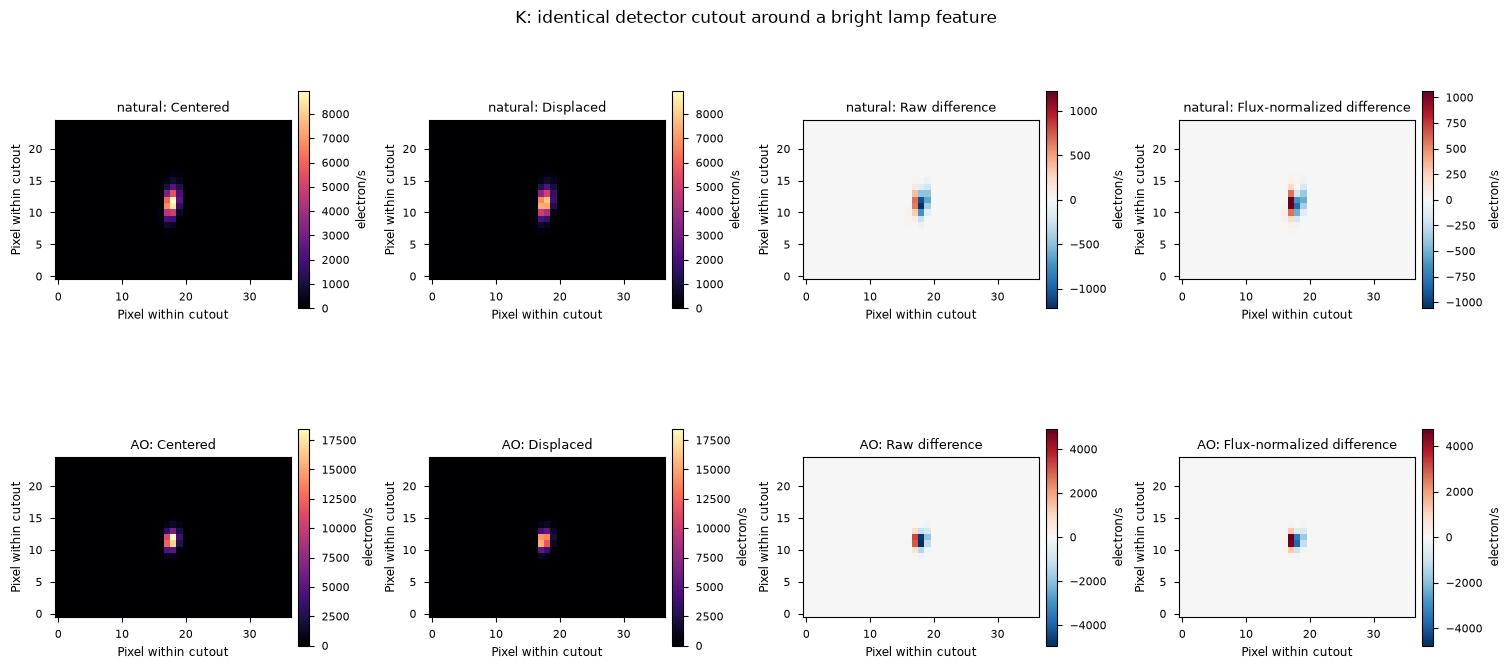

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, layout='constrained')
for column, label in enumerate(('natural', 'AO')):
    for source_kind, marker, alpha in [('lamp', '.', .35), ('synthetic', 'o', .9)]:
        data = centroids[(centroids.psf == label) & (centroids.source == source_kind)].sort_values('wavelength_um')
        axes[0, column].scatter(data.wavelength_um, data.measured_shift_pixel, s=8, marker=marker, alpha=alpha, label=source_kind)
        axes[1, column].scatter(data.wavelength_um, data.measured_shift_km_s, s=8, marker=marker, alpha=alpha)
        axes[2, column].scatter(data.wavelength_um, data.measured_shift_pixel-data.predicted_shift_pixel, s=8, marker=marker, alpha=alpha)
    prediction = centroids[(centroids.psf == label) & (centroids.source == 'synthetic')].sort_values('wavelength_um')
    for index, (_, order) in enumerate(prediction.groupby('trace')):
        axes[0, column].plot(order.wavelength_um, order.predicted_shift_pixel, color='k', lw=.8, label='illumination prediction' if index == 0 else None)
        axes[1, column].plot(order.wavelength_um, order.predicted_shift_km_s, color='k', lw=.8)
    axes[0, column].set_title(f'{label}; 0.33 arcsec slit, +0.0825 arcsec displacement')
    axes[0, column].legend(fontsize=8)
    axes[2, column].axhline(0, color='.4')
    axes[2, column].set_xlabel(r'Wavelength [$\mu$m]')
for ax, label in zip(axes[:, 0], ('Centroid shift [native pixel]', 'Centroid shift [km/s]', 'Measured minus predicted [pixel]')):
    ax.set_ylabel(label)
for ax in axes.flat:
    ax.grid(alpha=.2)
fig.savefig(output/'centroid_shifts.png', dpi=160)
plt.show()

for index, channel in enumerate(('B', 'G', 'R', 'YJ', 'H', 'K')):
    fig, axes = plt.subplots(2, 4, figsize=(15, 7), layout='constrained')
    for row, label in enumerate(('natural', 'AO')):
        first, second = [np.load(path, mmap_mode='r') for path in image_paths[label][index]]
        yy, xx = np.unravel_index(np.argmax(first), first.shape)
        region = (slice(max(0, yy-12), min(first.shape[0], yy+13)), slice(max(0, xx-18), min(first.shape[1], xx+19)))
        a, b = first[region], second[region]
        raw = b-a
        normalized = b*(a.sum(dtype=np.float64)/b.sum(dtype=np.float64))-a
        scale = max(a.max(), b.max())
        for ax, image, title in zip(axes[row], (a, b, raw, normalized), ('Centered', 'Displaced', 'Raw difference', 'Flux-normalized difference')):
            difference = 'difference' in title
            limit = max(abs(image.min()), abs(image.max())) if difference else scale
            rendered = ax.imshow(image, origin='lower', cmap='RdBu_r' if difference else 'magma', vmin=-limit if difference else 0, vmax=limit, interpolation='nearest')
            fig.colorbar(rendered, ax=ax, fraction=.046, pad=.03, label='electron/s')
            ax.set(title=f'{label}: {title}', xlabel='Pixel within cutout', ylabel='Pixel within cutout')
    fig.suptitle(f'{channel}: identical detector cutout around a bright lamp feature')
    fig.savefig(output/f'lamp_differences_{channel}.png', dpi=150)
    plt.show()

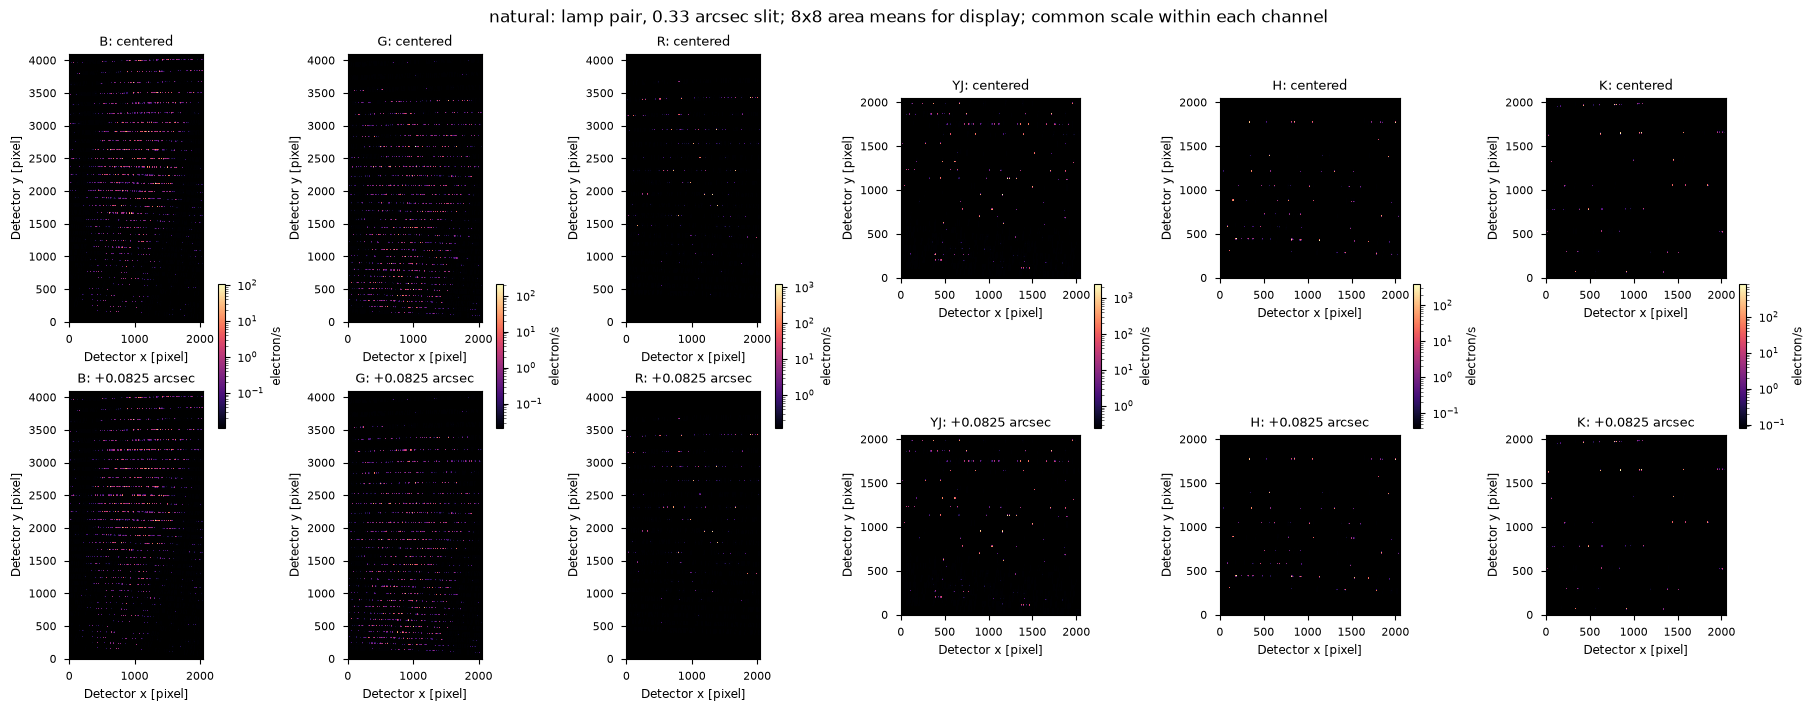

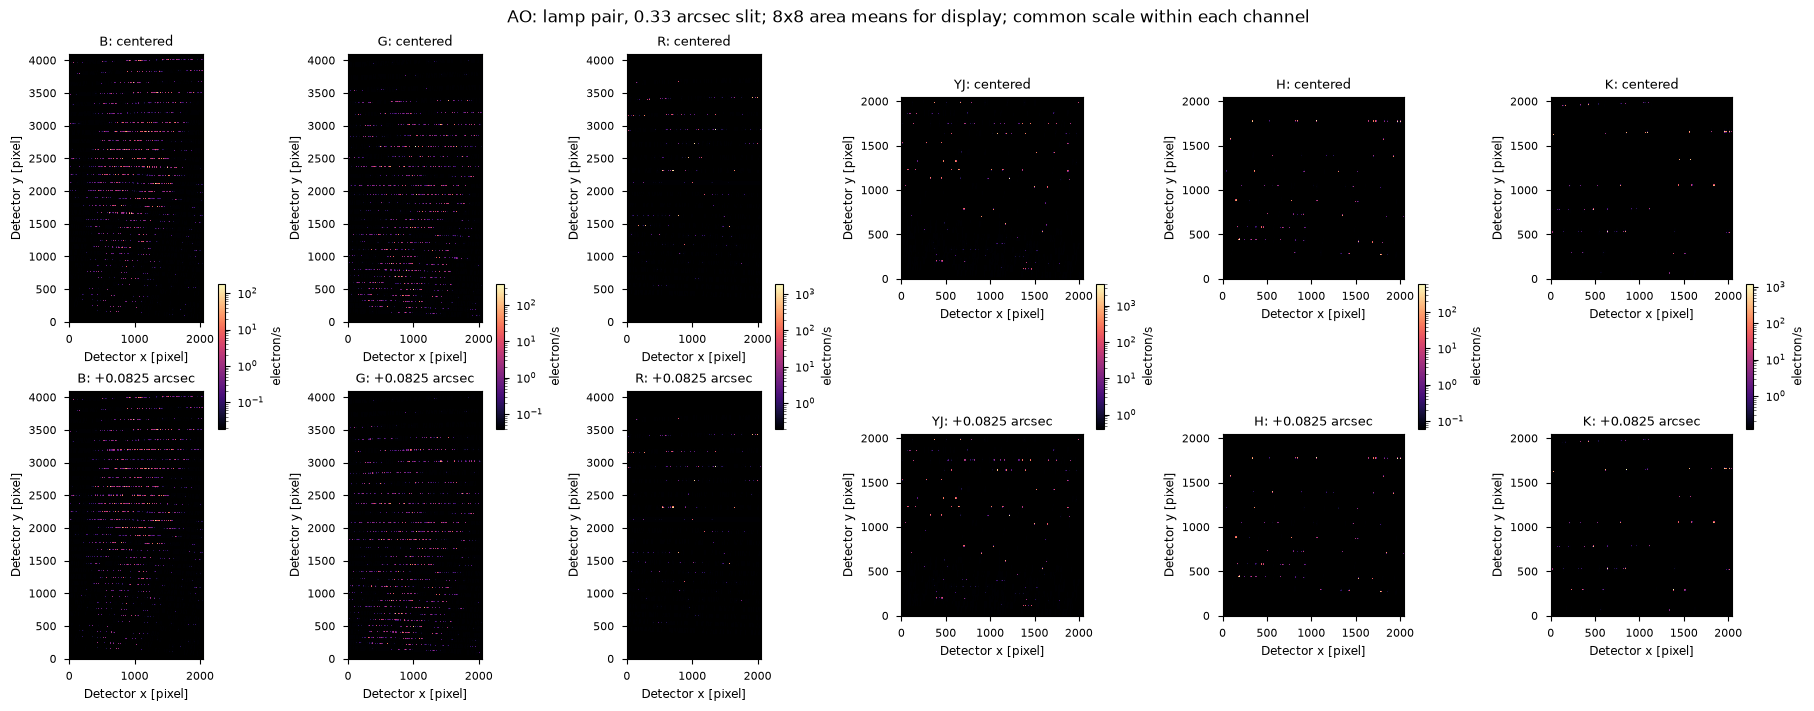

In [7]:
from matplotlib.colors import LogNorm

for label in ('natural', 'AO'):
    fig, axes = plt.subplots(2, 6, figsize=(18, 7), layout='constrained')
    for index, channel in enumerate(('B', 'G', 'R', 'YJ', 'H', 'K')):
        first, second = [np.load(path, mmap_mode='r') for path in image_paths[label][index]]
        ny, nx = first.shape
        # Area means retain every native pixel while making a full-frame overview legible.
        displays = [image.reshape(ny//8, 8, nx//8, 8).mean(axis=(1, 3)) for image in (first, second)]
        maximum = max(image.max() for image in displays)
        for row, image in enumerate(displays):
            rendered = axes[row, index].imshow(image, origin='lower', cmap=plt.colormaps['magma'].with_extremes(bad='black'), norm=LogNorm(vmin=maximum/10000, vmax=maximum), interpolation='nearest', extent=(-.5, nx-.5, -.5, ny-.5))
            axes[row, index].set(title=f'{channel}: {"centered" if row == 0 else "+0.0825 arcsec"}', xlabel='Detector x [pixel]')
        axes[0, index].set_ylabel('Detector y [pixel]')
        axes[1, index].set_ylabel('Detector y [pixel]')
        fig.colorbar(rendered, ax=axes[:, index], fraction=.04, pad=.02, label='electron/s')
    fig.suptitle(f'{label}: lamp pair, 0.33 arcsec slit; 8x8 area means for display; common scale within each channel')
    fig.savefig(output/f'lamp_frames_{label}.png', dpi=150)
    plt.show()

The CSV retains every selected line and both PSF cases. The lamp points pass an explicit nearest-neighbor separation criterion, but weak blends and real-list normalization can still affect them. Synthetic probes isolate numerical projection and detector sampling from those line-list effects. A centroid measured from native pixel centers has a pixel-phase response, especially when the line is narrow; compare the residuals with the [sampling convergence evidence](../validation/xshooter/data/line_convergence_errors.csv) rather than interpreting every deviation as an optical displacement.

Full centered/displaced rate arrays are saved locally beside the figures. The plotting cutouts use identical pixel coordinates in each pair, and no image interpolation is applied.